In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import ast

# Set the default Seaborn theme
sns.set_theme(style="ticks")

# Load the dataset and parse dates
df = pd.read_csv("../data_jobs.csv", parse_dates=["job_posted_date"])

# Convert string representations of lists into actual Python lists
df["job_skills"] = df["job_skills"].apply(lambda x: ast.literal_eval(x) if pd.notna(x) else x)

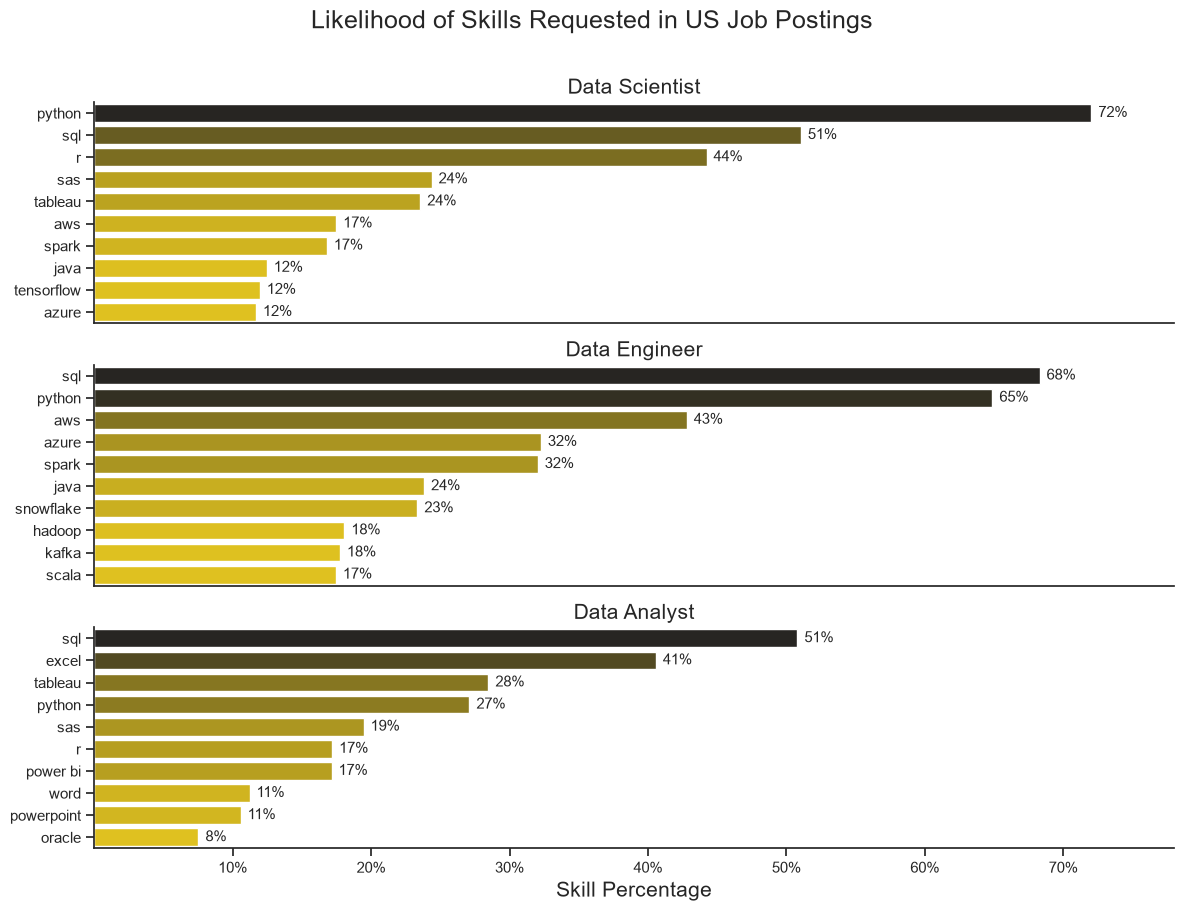

In [2]:
# Filter US job postings and exclude missing job titles
df_US = df[df["job_country"] == "United States"].dropna(subset="job_title_short")

# Job titles to visualize
job_titles = ["Data Scientist", "Data Engineer", "Data Analyst"]

# Count how often each skill appears for each job title
df_skills_count = (
    df_US
    .explode("job_skills")  # One row per skill
    .groupby(["job_title_short", "job_skills"], as_index=False)
    .size()
    .sort_values(by="size", ascending=False)
)

# Count the number of job postings for each job title
job_count = df_US['job_title_short'].value_counts()

# Combine skill counts with total job postings
df_skill_prec = df_skills_count.merge(job_count.reset_index(), on='job_title_short')

# Calculate the percentage of postings mentioning each skill
df_skill_prec['perc'] = 100 * (df_skill_prec['size'] / df_skill_prec['count'])

# Create one subplot for each job title
fig, ax = plt.subplots(3, 1, figsize=(12, 9))

for i,title in enumerate(job_titles):
    
    # Select the ten most frequently mentioned skills
    data = (
        df_skill_prec[df_skill_prec["job_title_short"] == title]
        .head(10)
    )

    # Plot skill percentages
    sns.barplot(
        data=data,
        x="perc",
        y="job_skills",
        ax=ax[i],
        hue="size",
        palette="dark:gold_r",
        legend=False,
    )

    # Add percentage labels at the end of each bar
    for n, per in enumerate(data['perc']):
        ax[i].text(per+0.5, n, f"{per:.0f}%", va="center", fontsize=11)

    # Format subplot labels and axes
    ax[i].set_title(title, fontsize=15)
    ax[i].set_ylabel("")
    ax[i].set_xlabel("")
    ax[i].tick_params(axis="y", labelsize=11)
    ax[i].set_xlim(right=78)
    ax[i].set_xticks([])

# Configure the shared visual style
ax[-1].set_xlabel("Skill Percentage", fontsize=15)
ax[-1].set_xticks(np.linspace(10, 70, 7), [f"{j}0%" for j in range(1, 8)])

fig.suptitle("Likelihood of Skills Requested in US Job Postings", fontsize=18, y=1.01)

sns.despine()
fig.tight_layout()